## Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.datasets import make_blobs
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from pyod.models.iforest import IForest
from pyod.models.dif import DIF
from pyod.models.loda import LODA
from pyod.utils.utility import standardizer

np.random.seed(0)

## Exercise 1

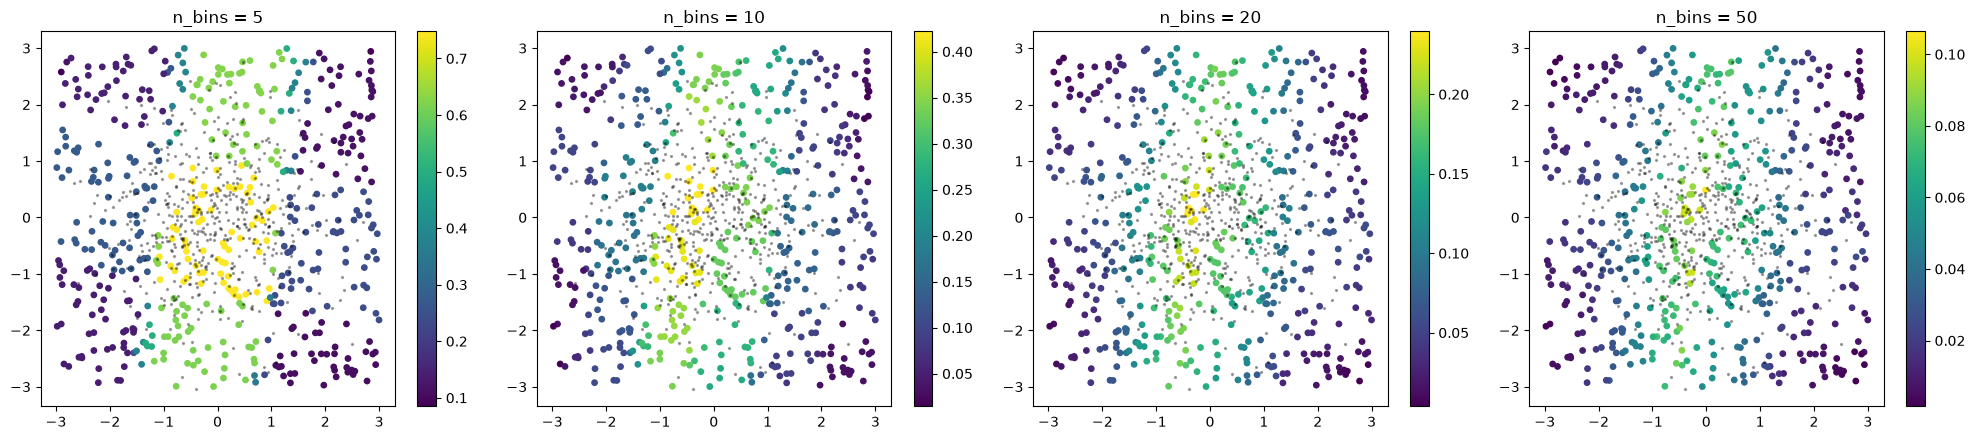

In [3]:
X_train, _ = make_blobs(n_samples=500, n_features=2, centers=[(0, 0)], cluster_std=1.0, random_state=0)
X_test = np.random.uniform(-3, 3, size=(500, 2))

def make_projections(n_proj=5, d=2):
    W = np.random.multivariate_normal(np.zeros(d), np.eye(d), size=n_proj)
    return W / np.linalg.norm(W, axis=1, keepdims=True)      # unit length

def fit_histograms(X, W, n_bins):
    hists = []
    for w in W:
        z = X @ w
        margin = 0.5 * (z.max() - z.min())                    # range larger than projected data
        counts, edges = np.histogram(z, bins=n_bins, range=(z.min() - margin, z.max() + margin))
        hists.append((counts / counts.sum(), edges))          # probability of each bin
    return hists

def score(X, W, hists):
    probs = np.zeros((len(X), len(W)))
    for j, (w, (p, edges)) in enumerate(zip(W, hists)):
        idx = np.digitize(X @ w, edges) - 1                   # bin index of each projected point
        inside = (idx >= 0) & (idx < len(p))
        probs[inside, j] = p[idx[inside]]                     # outside the range -> probability 0
    return probs.mean(axis=1)

W = make_projections(5)
fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, nb_ in zip(axs, [5, 10, 20, 50]):
    hists = fit_histograms(X_train, W, nb_)
    s = score(X_test, W, hists)
    sc = ax.scatter(X_test[:, 0], X_test[:, 1], c=s, cmap="viridis", s=15)
    ax.scatter(X_train[:, 0], X_train[:, 1], c="k", s=2, alpha=0.3)
    ax.set_title(f"n_bins = {nb_}")
    plt.colorbar(sc, ax=ax)
plt.tight_layout(); plt.show()

## Exercise 2

d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\datalo

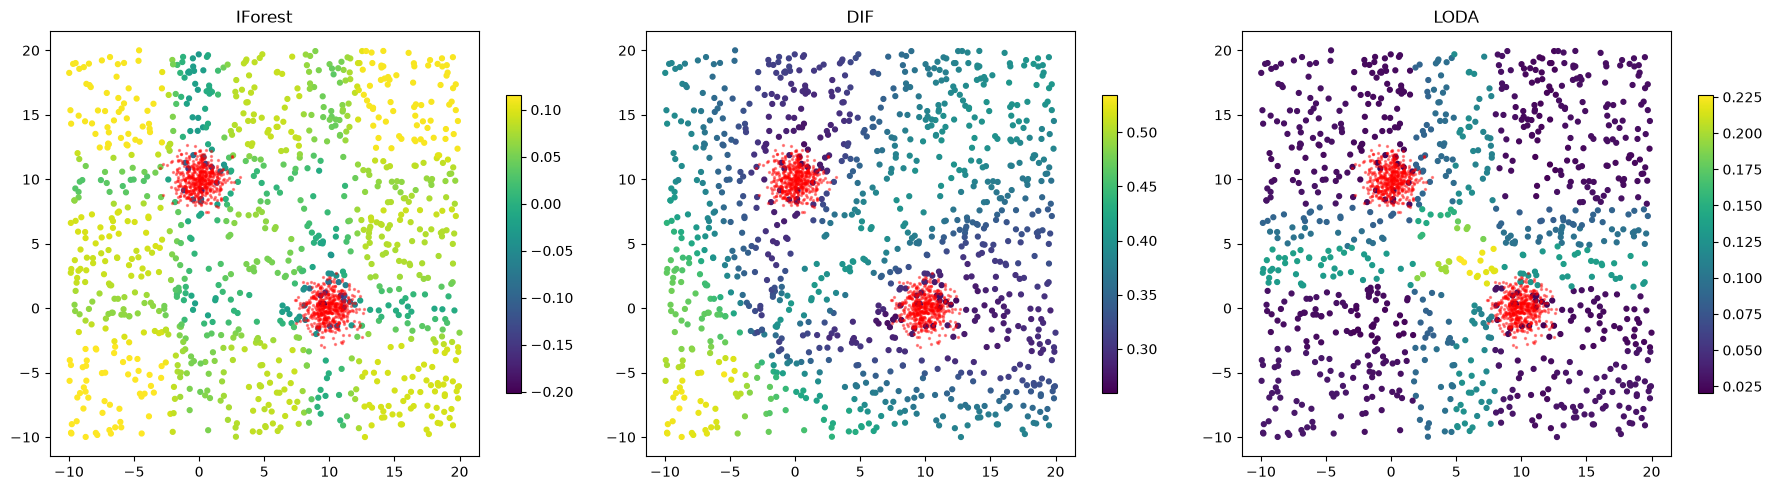

In [4]:
def plot_maps(X_train, X_test, models, dim):
    fig = plt.figure(figsize=(6 * len(models), 5))
    for i, (name, clf) in enumerate(models):
        clf.fit(X_train)
        s = clf.decision_function(X_test)
        if dim == 2:
            ax = fig.add_subplot(1, len(models), i + 1)
            sc = ax.scatter(X_test[:, 0], X_test[:, 1], c=s, cmap="viridis", s=12)
            ax.scatter(X_train[:, 0], X_train[:, 1], c="r", s=2, alpha=0.4)
        else:
            ax = fig.add_subplot(1, len(models), i + 1, projection="3d")
            sc = ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=s, cmap="viridis", s=8)
        ax.set_title(name); plt.colorbar(sc, ax=ax, shrink=0.7)
    plt.tight_layout(); plt.show()

X_train2, _ = make_blobs(n_samples=[500, 500], centers=[(10, 0), (0, 10)], cluster_std=1, n_features=2, random_state=0)
X_test2 = np.random.uniform(-10, 20, size=(1000, 2))

plot_maps(X_train2, X_test2, [
    ("IForest", IForest(contamination=0.02, random_state=0)),
    ("DIF",     DIF(contamination=0.02, random_state=0)),
    ("LODA",    LODA(contamination=0.02)),
], dim=2)

### Different hidden layer sizes for DIF and different bins for LODA

d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\datalo

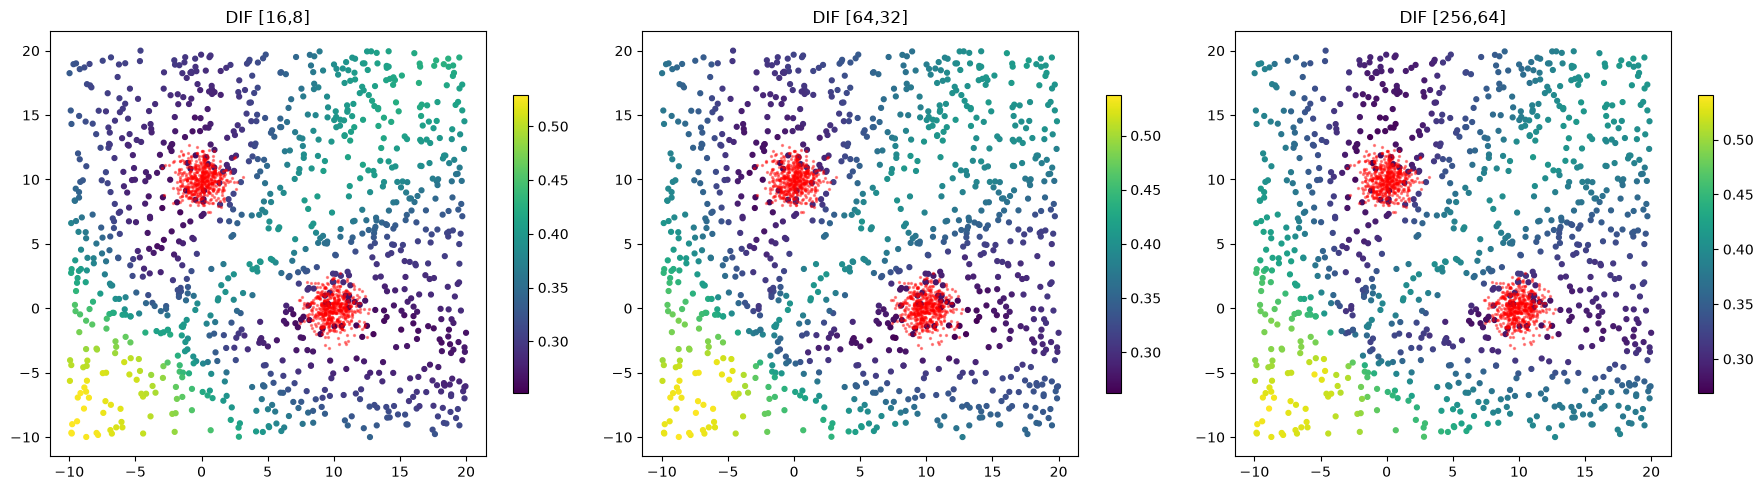

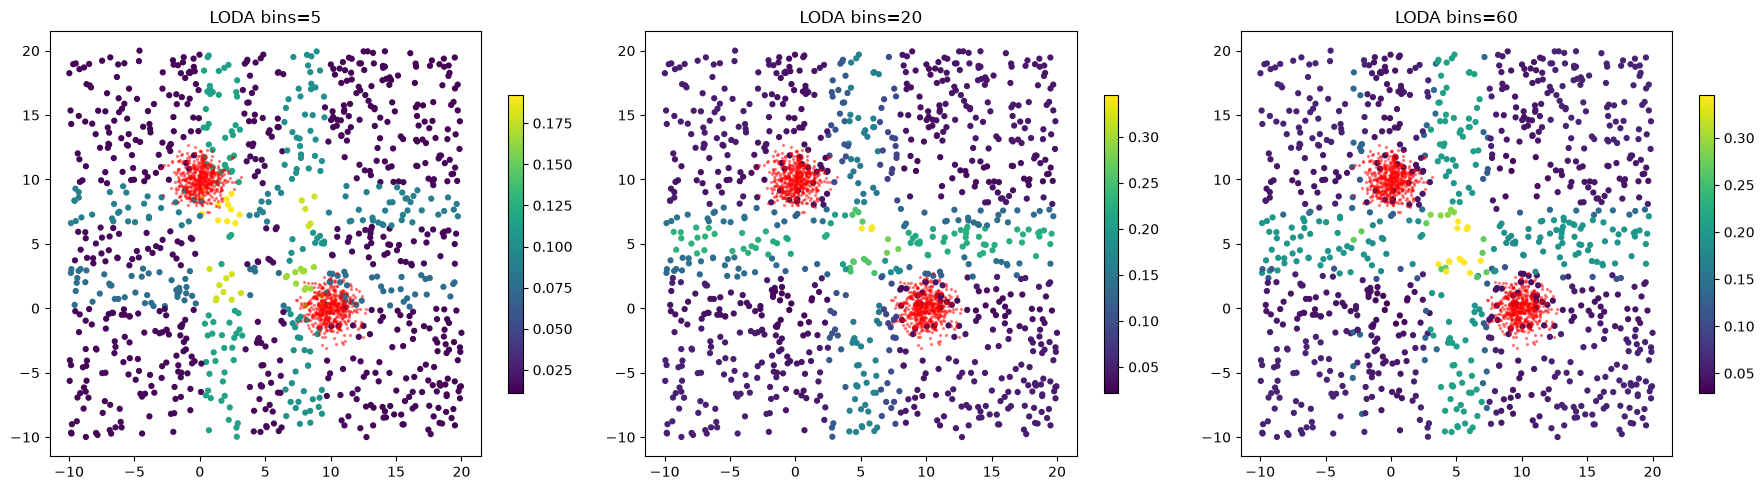

In [5]:
plot_maps(X_train2, X_test2, [
    ("DIF [16,8]",   DIF(hidden_neurons=[16, 8],    contamination=0.02, random_state=0)),
    ("DIF [64,32]",  DIF(hidden_neurons=[64, 32],   contamination=0.02, random_state=0)),
    ("DIF [256,64]", DIF(hidden_neurons=[256, 64],  contamination=0.02, random_state=0)),
], dim=2)
plot_maps(X_train2, X_test2, [
    ("LODA bins=5",  LODA(n_bins=5,  contamination=0.02)),
    ("LODA bins=20", LODA(n_bins=20, contamination=0.02)),
    ("LODA bins=60", LODA(n_bins=60, contamination=0.02)),
], dim=2)

### 3D version

d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\datalo

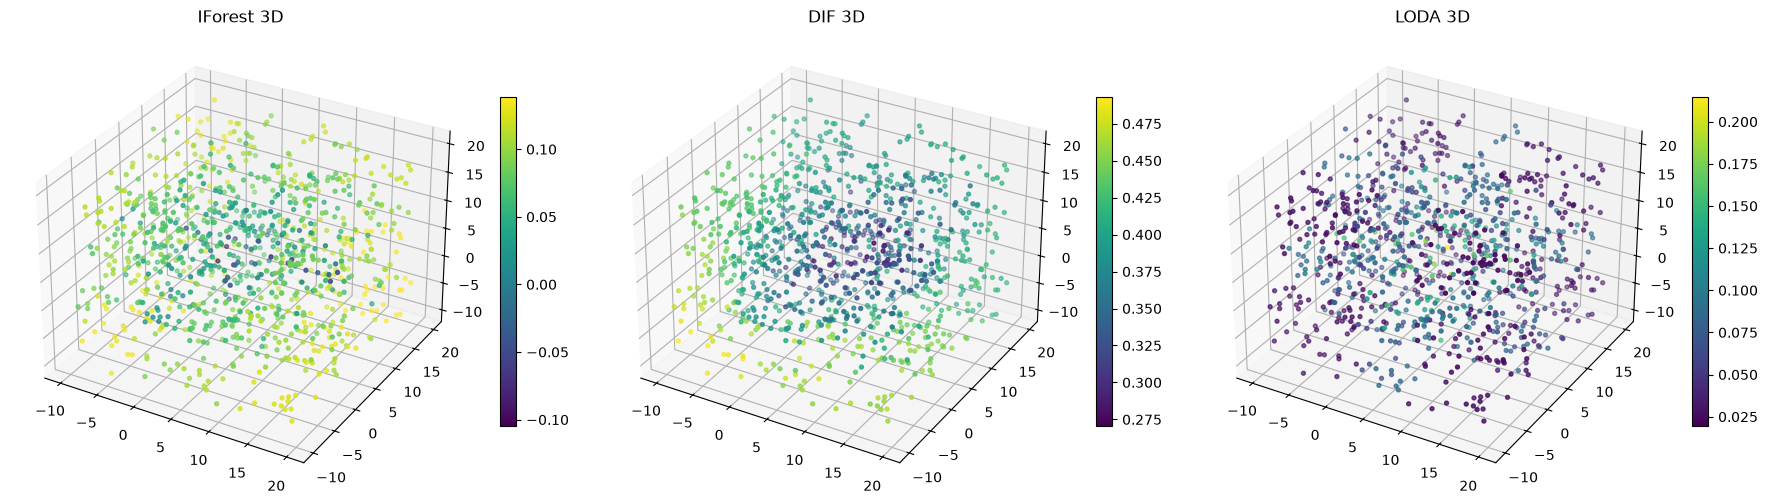

In [6]:
X_train3, _ = make_blobs(n_samples=[500, 500], centers=[(0, 10, 0), (10, 0, 10)], cluster_std=1, n_features=3, random_state=0)
X_test3 = np.random.uniform(-10, 20, size=(1000, 3))

plot_maps(X_train3, X_test3, [
    ("IForest 3D", IForest(contamination=0.02, random_state=0)),
    ("DIF 3D",     DIF(contamination=0.02, random_state=0)),
    ("LODA 3D",    LODA(contamination=0.02)),
], dim=3)

## Exercise 3

In [7]:
data = loadmat("shuttle.mat")
X, y = data["X"], data["y"].ravel()
print(X.shape, "contamination =", round(y.mean(), 4))

(49097, 9) contamination = 0.0715


In [8]:
import time
n_splits = 10
res = {"IForest": [], "LODA": [], "DIF": []}

for seed in range(n_splits):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.4, random_state=seed, stratify=y)
    X_tr, X_te = standardizer(X_tr, X_te)
    models = {
        "IForest": IForest(contamination=y.mean(), random_state=seed),
        "LODA":    LODA(contamination=y.mean()),
        "DIF":     DIF(contamination=y.mean(), random_state=seed),
    }
    for name, clf in models.items():
        t0 = time.time()
        clf.fit(X_tr)
        ba  = balanced_accuracy_score(y_te, clf.predict(X_te))
        auc = roc_auc_score(y_te, clf.decision_function(X_te))
        res[name].append((ba, auc))
        print(f"split {seed} {name:8s} BA={ba:.3f}  AUC={auc:.3f}  ({time.time()-t0:.1f}s)")

print()
for name, r in res.items():
    r = np.array(r)
    print(f"{name:8s} mean BA = {r[:,0].mean():.3f} (+/- {r[:,0].std():.3f})   mean ROC AUC = {r[:,1].mean():.3f} (+/- {r[:,1].std():.3f})")

split 0 IForest  BA=0.982  AUC=0.998  (1.2s)
split 0 LODA     BA=0.477  AUC=0.086  (0.4s)


d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\datalo

split 0 DIF      BA=0.860  AUC=0.978  (199.9s)
split 1 IForest  BA=0.952  AUC=0.996  (1.3s)
split 1 LODA     BA=0.599  AUC=0.348  (0.4s)


d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\datalo

split 1 DIF      BA=0.837  AUC=0.972  (514.4s)
split 2 IForest  BA=0.976  AUC=0.998  (2.3s)
split 2 LODA     BA=0.599  AUC=0.425  (0.8s)


d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\datalo

... (11 outputs left out)

d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\datalo

split 8 DIF      BA=0.894  AUC=0.980  (421.1s)
split 9 IForest  BA=0.973  AUC=0.997  (2.0s)
split 9 LODA     BA=0.652  AUC=0.752  (0.9s)


d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\SEM1\anomaly_detection\venv\Lib\site-packages\torch\utils\data\datalo

split 9 DIF      BA=0.840  AUC=0.974  (312.8s)

IForest  mean BA = 0.971 (+/- 0.009)   mean ROC AUC = 0.997 (+/- 0.001)
LODA     mean BA = 0.598 (+/- 0.116)   mean ROC AUC = 0.574 (+/- 0.265)
DIF      mean BA = 0.817 (+/- 0.038)   mean ROC AUC = 0.970 (+/- 0.006)
